# 07 · URL-only models with the shortcuts removed

Notebook 06 showed that every legitimate URL is a bare `https://www.<domain>` homepage. A URL-only model can score ~99.7% just from *how the URL starts* and *whether it has a path*.

Here we retrain the same URL-only models on four **views** of each URL (`phishguard.urls.URL_VIEWS`), each removing more of the shortcut:

| View | `https://www.login.paypal-secure.top/x?id=7` becomes | Removes |
|---|---|---|
| **raw URL** | `https://www.login.paypal-secure.top/x?id=7` | nothing (Milestone 2 setting) |
| **no scheme/www** | `login.paypal-secure.top/x?id=7` | the `https://www.` prefix |
| **domain only** | `login.paypal-secure.top` | prefix, path and query |
| **registered domain** | `paypal-secure.top` | also subdomains, and hosting-platform customers collapse to the platform |

We call the later views **shortcut-reduced**, not "honest". Section 3 shows that even the domain still carries a collection difference.

Everything is run over **5 site-owner splits** (mean ± sd).

In [1]:
import matplotlib.pyplot as plt
from matplotlib.container import BarContainer
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

from phishguard.data import load_clean, TARGET
from phishguard.urls import URL_VIEWS, TLD_EXTRACT
from phishguard.features import extract_features
from phishguard.evaluate import evaluate
from phishguard.experiment import run, summary_table
from phishguard.modeling import param_grid

df = load_clean()
y = df[TARGET]
example = pd.Series(["https://www.login.paypal-secure.top/x?id=7", "https://www.wikipedia.org"])
pd.DataFrame({name: view(example) for name, view in URL_VIEWS.items()})

,raw URL,no scheme/www,domain only,registered domain
0,https://www.login.paypal-secure.top/x?id=7,login.paypal-secure.top/x?id=7,login.paypal-secure.top,paypal-secure.top
1,https://www.wikipedia.org,wikipedia.org,wikipedia.org,wikipedia.org


## 1. Both URL-only models on every view

- **Char n-gram + Logistic Regression.** `C` is re-tuned on validation for every view and split.
- **XGBoost on the URL features.** `max_depth` is re-tuned too. In the domain-only views many features are constant (path, query, `is_https` …), so XGBoost effectively uses fewer of them.

In [2]:
def make_ngram(C):
    return make_pipeline(
        TfidfVectorizer(analyzer="char", ngram_range=(1, 4), min_df=2, sublinear_tf=True, dtype=np.float32),
        LogisticRegression(C=C, solver="liblinear", max_iter=3000),
    )

make_xgb = lambda max_depth: XGBClassifier(max_depth=max_depth, n_estimators=500, learning_rate=0.1,
                                           subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42)
experiments, constant_features = {}, {}
for view_name, view in URL_VIEWS.items():
    urls = view(df["URL"])
    experiments[(view_name, "Char n-gram LogReg")] = run(
        f"Char n-gram LogReg | {view_name}", make_ngram, param_grid(C=[1.0, 3.0, 10.0]),
        urls, y, df, features=view_name, group="m3_views")
    features = extract_features(urls)
    constant_features[view_name] = int((features.nunique() == 1).sum())
    experiments[(view_name, "XGBoost (URL features)")] = run(
        f"XGBoost URL features | {view_name}", make_xgb, param_grid(max_depth=[6, 10]),
        features, y, df, features=view_name, group="m3_views")

print("constant features per view (of 40):", constant_features)
summary_table(experiments.values(), metrics=("accuracy", "f1", "roc_auc", "pr_auc", "tpr_at_fpr_1pct"))

constant features per view (of 40): {'raw URL': 0, 'no scheme/www': 1, 'domain only': 16, 'registered domain': 17}


,accuracy (%),f1 (%),roc_auc,pr_auc,tpr_at_fpr_1pct (%),"accuracy, seed 42 [95% CI]"
model,,,,,,
Char n-gram LogReg | raw URL,99.70 ± 0.03,99.64 ± 0.04,0.9985 ± 0.0002,0.9988 ± 0.0002,99.53 ± 0.06,"99.75% [99.69%, 99.81%]"
XGBoost URL features | raw URL,99.64 ± 0.03,99.58 ± 0.03,0.9972 ± 0.0004,0.9979 ± 0.0003,99.35 ± 0.09,"99.69% [99.62%, 99.75%]"
Char n-gram LogReg | no scheme/www,89.18 ± 0.59,86.01 ± 0.84,0.9376 ± 0.0034,0.9416 ± 0.0034,73.52 ± 1.73,"89.73% [88.70%, 90.79%]"
XGBoost URL features | no scheme/www,85.95 ± 0.95,80.96 ± 1.57,0.8893 ± 0.0077,0.9032 ± 0.0075,66.99 ± 2.78,"87.03% [86.01%, 88.28%]"
Char n-gram LogReg | domain only,86.27 ± 0.89,81.89 ± 1.29,0.9162 ± 0.0058,0.9194 ± 0.0063,63.85 ± 2.64,"87.33% [86.14%, 88.57%]"
XGBoost URL features | domain only,81.43 ± 1.15,73.86 ± 1.85,0.8473 ± 0.0074,0.8613 ± 0.0087,54.59 ± 3.35,"80.19% [74.55%, 83.56%]"
Char n-gram LogReg | registered domain,82.49 ± 1.93,75.83 ± 3.20,0.8945 ± 0.0082,0.8934 ± 0.0096,52.92 ± 4.07,"85.03% [83.38%, 86.71%]"
XGBoost URL features | registered domain,72.82 ± 0.70,55.87 ± 1.32,0.7698 ± 0.0115,0.7697 ± 0.0109,34.34 ± 2.18,"72.65% [65.92%, 77.31%]"


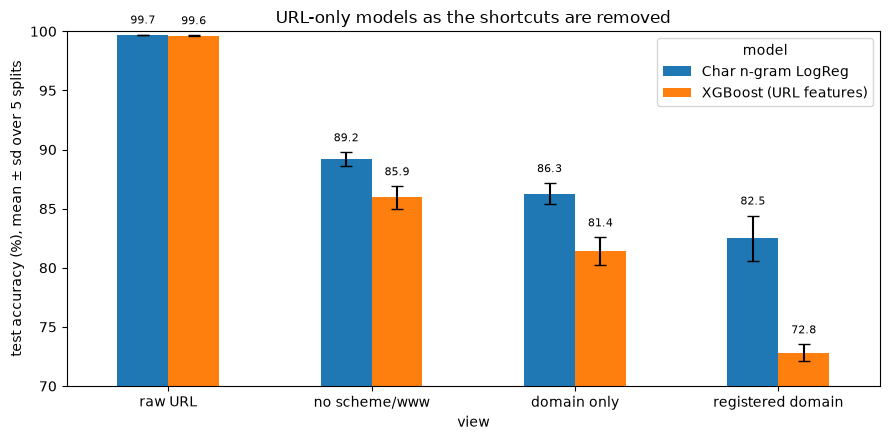

In [3]:
acc = pd.DataFrame([{"view": v, "model": m, "mean": e.summary.loc["accuracy", "mean"] * 100,
                     "sd": e.summary.loc["accuracy", "sd"] * 100} for (v, m), e in experiments.items()])
means = acc.pivot(index="view", columns="model", values="mean").loc[list(URL_VIEWS)]
sds = acc.pivot(index="view", columns="model", values="sd").loc[list(URL_VIEWS)]
ax = means.plot.bar(yerr=sds, capsize=4, figsize=(9, 4.5), rot=0)
ax.set_ylim(70, 100)
ax.set_ylabel("test accuracy (%), mean ± sd over 5 splits")
ax.set_title("URL-only models as the shortcuts are removed")
for container in ax.containers:
    if isinstance(container, BarContainer):
        ax.bar_label(container, fmt="%.1f", fontsize=8, padding=6)
plt.tight_layout()
plt.show()

## 2. What does the domain-only model look at? (seed-42 model)

In [4]:
ref = experiments[("domain only", "Char n-gram LogReg")]
vectorizer, logreg = ref.reference.model.named_steps.values()
weights = pd.Series(logreg.coef_[0], index=vectorizer.get_feature_names_out())
pd.DataFrame({
    "→ phishing": weights.nlargest(20).index, "w": weights.nlargest(20).round(1).values,
    "→ legitimate": weights.nsmallest(20).index, "w ": weights.nsmallest(20).round(1).values,
})

,→ phishing,w,→ legitimate,w
0,.cf,13.6,.go,-10.0
1,.ga,11.5,.gov,-9.5
2,.w,11.3,.edu,-8.7
3,.ml,10.7,.jp,-8.1
4,3,9.7,.ed,-7.8
5,-,9.7,.de,-7.2
6,x,9.6,.com,-7.1
7,6,9.2,.it,-7.0
8,.top,9.2,.cz,-6.6
9,8,9.0,.or,-6.3


## 3. Even the domain still carries a collection difference

The legitimate list consists of popular *registered domains*: almost none have an extra subdomain or sit on a hosting platform. A rule with **no learning** shows how far that alone goes:

> phishing if the domain has a subdomain, **or** is on a hosting platform, **or** is an IP address, **or** contains a digit, **or** contains `xn--`

In [5]:
_, _, test_idx = ref.reference_splits
domains = URL_VIEWS["domain only"](df["URL"]).loc[test_idx]
extracted = domains.map(TLD_EXTRACT)
structured = (extracted.map(lambda e: bool(e.subdomain)) | extracted.map(lambda e: e.is_private)
              | domains.str.match(r"^\d+(\.\d+){3}$") | domains.str.contains(r"\d") | domains.str.contains("xn--"))
yt = y.loc[test_idx]
print("share with such structure — legitimate: {:.1%}, phishing: {:.1%}".format(
    structured[yt == 0].mean(), structured[yt == 1].mean()))
pd.Series(evaluate(yt, structured.astype(int)))[["accuracy", "precision", "recall"]].round(4)

share with such structure — legitimate: 6.2%, phishing: 56.9%


accuracy     0.7812
precision    0.8705
recall       0.5691
dtype: float64

So part of the domain-only score is still this structural difference. We therefore also report the model **separately** for the two kinds of test domains:

In [6]:
pred = (ref.reference.test_prob >= ref.reference.threshold).astype(int)
breakdown = {}
for name, mask in {"structured domains": structured.to_numpy(), "bare registered domains": ~structured.to_numpy()}.items():
    m = evaluate(yt[mask], ref.reference.test_prob[mask], ref.reference.threshold)
    breakdown[name] = {"rows": int(mask.sum()), "phishing share": yt[mask].mean(),
                       "accuracy": m["accuracy"], "recall": m["recall"], "roc_auc": m["roc_auc"]}
pd.DataFrame(breakdown).T.round(4)

,rows,phishing share,accuracy,recall,roc_auc
structured domains,9744.0,0.8705,0.921,0.9309,0.9660
bare registered domains,25386.0,0.2530,0.855,0.5323,0.8437


## 4. Counting each domain once

Some phishing domains repeat many times in the test set (e.g. `ipfs.io` gateways). Each row counts once in our metrics, so a few frequent, easy domains can lift the score. Here is the seed-42 model with every **distinct domain counted once** (majority label, mean probability):

In [7]:
per_domain = pd.DataFrame({"domain": domains, "y": yt, "prob": ref.reference.test_prob}).groupby("domain").agg(
    y=("y", lambda s: int(s.mean() >= 0.5)), prob=("prob", "mean"))
print("test rows:", len(domains), "| distinct domains:", len(per_domain))
print("top domains:", domains.value_counts().head(5).to_dict())
pd.DataFrame({
    "per row": evaluate(yt, ref.reference.test_prob, ref.reference.threshold),
    "per distinct domain": evaluate(per_domain["y"], per_domain["prob"], ref.reference.threshold),
}).loc[["accuracy", "recall", "precision", "roc_auc"]].round(4)

test rows: 35130 | distinct domains: 31828
top domains: {'ipfs.io': 1115, 'gateway.pinata.cloud': 232, 'gateway.ipfs.io': 216, 'u1965047.plsk.regruhosting.ru': 167, 'tinyurl.com': 135}


,per row,per distinct domain
accuracy,0.8733,0.8714
recall,0.7591,0.7216
precision,0.9293,0.9069
roc_auc,0.9213,0.9098


## 5. Errors on the domain-only view (seed 42, validation set)

In [8]:
_, val_idx, _ = ref.reference_splits
val_domains = URL_VIEWS["domain only"](df["URL"]).loc[val_idx]
val_prob = pd.Series(ref.reference.val_prob, index=val_idx)
yv = y.loc[val_idx]
pd.DataFrame({
    "caught phishing (highest score)": val_domains.loc[val_prob[yv == 1].nlargest(8).index].values,
    "missed phishing (lowest score)": val_domains.loc[val_prob[yv == 1].nsmallest(8).index].values,
    "legit flagged as phishing": val_domains.loc[val_prob[yv == 0].nlargest(8).index].values,
})

,caught phishing (highest score),missed phishing (lowest score),legit flagged as phishing
0,bafybeigqfmp6iucxw5723sybqjnpm26uiufqz74jd7ufb...,smithtony.co.uk,wwwxxx.club
1,bafybeiewh3pj7xqg6zmcrqggwmmcqw2bd2zlo5c264ojg...,enic.ca,iatuc0e2xz.ga
2,bafybeicrq42t3uoi53hf2hhntwq74hfapj5rutrp6ejli...,emadella.it,nsupdate.info
3,bafybeid24of7rxeri745nfznxdwzzxq764pkapwtgqbff...,oryanomer.com,dns.com
4,bafybeiai3z3i456cn25i7x7laemtf3g5mhd4lomkmypw5...,arys.org,radix.website
5,bafybeihzbhh5lnuwqhefhykl6tkvm55kl7krjqxvsxn3j...,edapt.education,joycasino0kz.xyz
6,bafybeicx6pb4yskej4kcdnxre6zf3h352cflfpjfz3gj6...,armenpress.org,hotelservices.online
7,bafybeicx6pb4yskej4kcdnxre6zf3h352cflfpjfz3gj6...,mastertape.org,update.ph


## What we learned (mean ± sd over 5 splits)

| View | Char n-gram LogReg | XGBoost (URL features) |
|---|---|---|
| raw URL | 99.70 ± 0.03% | 99.64 ± 0.03% |
| no scheme/www | 89.18 ± 0.59% | 85.95 ± 0.95% |
| domain only | **86.27 ± 0.89%** | 81.43 ± 1.15% |
| registered domain | 82.49 ± 1.93% | 72.82 ± 0.70% |

1. **About 13 points of URL-only accuracy come from the `https://www.` prefix and from whether there's a path.** These describe how PhiUSIIL was collected (legitimate = homepages), not phishing.
2. **The shortcut-reduced URL-only score is about 86%** from the domain name alone, and ~82% from the registered domain alone. That's far above always guessing "legitimate" (57.6%), so the name carries real signal: free TLDs (`.cf`, `.ga`, `.ml`, `.top`), digits and hyphens, IPFS and free-hosting names.
3. **Part of that is still structure, not the name.** A no-learning rule (subdomain / hosting platform / IP / digit / `xn--` → phishing) gets 78% on its own, because only 6.2% of legitimate domains have such structure against 56.9% of phishing. On **bare registered domains**, the n-gram model reaches 85.5% accuracy but catches only 53% of phishing (ROC-AUC 0.84).
4. **Repeated domains barely matter:** counting each distinct domain once gives 87.1% instead of 87.3% (seed 42).
5. **Character n-grams beat hand-written features once the shortcuts are gone** (86.3% vs 81.4%). The information is in the characters of the name, which counts miss. That's the motivation for the character-level CNN and BiLSTM in Milestone 4.
6. **Missed phishing look like ordinary small sites** (`smithtony.co.uk`, `enic.ca`). These are probably compromised legitimate sites, which no URL-only model can recognise from the name.
7. **Real traffic:** with seed-42 recall 76% and a false-alarm rate of 4.3%, precision at a 1% phishing rate would be only about 15%. A domain-only detector is a useful signal, not a standalone filter.

**Decision D10:** every URL model from Milestone 4 on is reported on **raw URL** (to compare with published work), **domain only** and **registered domain** (the shortcut-reduced numbers), each as mean ± sd over 5 splits.